<a href="https://colab.research.google.com/github/mujtaba-mohiyuddin/ucb-traffic-sign-recognition/blob/main/20261010_UCB_Assignment_Week23_GradientBoosting_vs_AdaBoost_Churn2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 23 Practice Problem 2: Gradient Boosting vs AdaBoost on Customer Churn

**Dataset:** Telco Customer Churn (7,043 customers, 19 usable features). **Target:** `Churn` (Yes/No).

**Goal:** Build and compare boosting-based ensemble models (AdaBoost and Gradient Boosting) for churn prediction, tune their key hyperparameters with cross-validation, and analyze performance.

**Boosting in one line:** both methods build many small models one after another, each trying to fix the previous ones' mistakes.
- **AdaBoost** re-weights the training rows: customers the model got wrong get more weight, so the next model focuses on them.
- **Gradient Boosting** fits each new tree to the *remaining errors* (the gradient of the loss) of the current ensemble.

**Runtime note:** the Gradient Boosting grid search (36 combinations x 5 folds) can take several minutes in Colab.

## 1. Load and Prepare

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
# Load the dataset from the URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Drop customerID - it identifies a customer but carries no predictive information
df = df.drop(columns="customerID")

# TotalCharges is stored as text because a few rows hold a blank string (brand-new customers).
# errors="coerce" turns those blanks into NaN, then we drop those rows.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with blank TotalCharges:", df["TotalCharges"].isnull().sum())

df = df.dropna().reset_index(drop=True)
print("Shape after dropping those rows:", df.shape)

Rows with blank TotalCharges: 11
Shape after dropping those rows: (7032, 20)


Churn
0    5163
1    1869
Name: count, dtype: int64

Churn rate: 26.6%  (imbalanced - keep this in mind when reading accuracy)


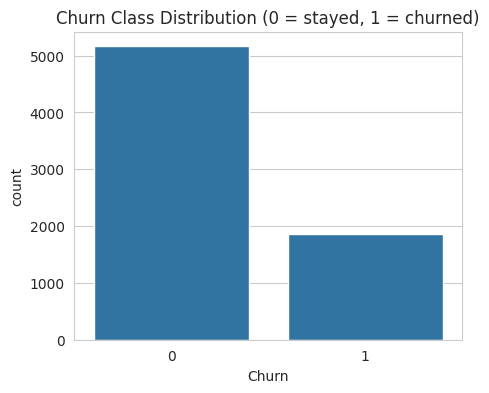

In [4]:
# Encode the target: Churn -> 1 if "Yes", else 0
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print(df["Churn"].value_counts())
print(f"\nChurn rate: {df['Churn'].mean()*100:.1f}%  (imbalanced - keep this in mind when reading accuracy)")

plt.figure(figsize=(5,4))
sns.countplot(x="Churn", data=df)
plt.title("Churn Class Distribution (0 = stayed, 1 = churned)")
plt.show()

In [5]:
# One-hot encode categorical features (drop_first=True avoids redundant columns)
y = df["Churn"]
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=int)
print("Feature matrix shape after encoding:", X.shape)

# Split into train (75%) and test (25%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Feature matrix shape after encoding: (7032, 30)
Train: (5274, 30) Test: (1758, 30)


In [6]:
# Standardize numeric features: fit on TRAIN only, then transform both
# (fitting on the test set would leak information about it into training)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5274.00,5274.00,5274.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.28,-1.54,-1.00
25%,-0.95,-0.98,-0.83
50%,-0.14,0.19,-0.39
75%,0.92,0.84,0.66
max,1.61,1.79,2.84


In [7]:
# Helper: evaluate a fitted model on the test set (metrics are for the 'churn' class)
def evaluate(model, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }
    print(f"--- {name} ---")
    print(f"Accuracy:  {metrics['Accuracy']:.4f}")
    print(f"Precision: {metrics['Precision']:.4f}")
    print(f"Recall:    {metrics['Recall']:.4f}")
    print(f"F1-score:  {metrics['F1']:.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print()
    return metrics

## 2. Baseline: AdaBoost

In [8]:
ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
ada_metrics = evaluate(ada, "AdaBoost (baseline)")

--- AdaBoost (baseline) ---
Accuracy:  0.7935
Precision: 0.6346
Recall:    0.4891
F1-score:  0.5524
Confusion Matrix:
[[1171  129]
 [ 234  224]]



## 3. Baseline: Gradient Boosting

In [9]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)
gb_metrics = evaluate(gb, "Gradient Boosting (baseline)")

--- Gradient Boosting (baseline) ---
Accuracy:  0.7918
Precision: 0.6271
Recall:    0.4956
F1-score:  0.5537
Confusion Matrix:
[[1165  135]
 [ 231  227]]



In [10]:
# Side-by-side comparison of the two baselines
baseline_df = pd.DataFrame([ada_metrics, gb_metrics]).set_index("Model")
baseline_df.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
AdaBoost (baseline),0.7935,0.6346,0.4891,0.5524,0.8361
Gradient Boosting (baseline),0.7918,0.6271,0.4956,0.5537,0.8342


**Reading the comparison:** only about a quarter of customers churn, so accuracy can look decent even when the model misses many churners. Look at **recall** (what share of real churners were caught), **F1**, and the bottom-left cell of each confusion matrix (churners the model missed). The two baselines are usually close; check your actual numbers before drawing a conclusion.

## 4. Tune AdaBoost
`GridSearchCV` with 5-fold cross-validation over `n_estimators` and `learning_rate`. The learning rate controls how much each new model may change the ensemble: small values learn slowly and usually need more estimators.

In [11]:
ada_param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 0.5, 1.0]
}

ada_grid = GridSearchCV(AdaBoostClassifier(random_state=42), ada_param_grid,
                        cv=5, scoring="accuracy", n_jobs=-1)
ada_grid.fit(X_train, y_train)

print("Best AdaBoost parameters:", ada_grid.best_params_)
print(f"Best CV accuracy: {ada_grid.best_score_:.4f}")

Best AdaBoost parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV accuracy: 0.8075


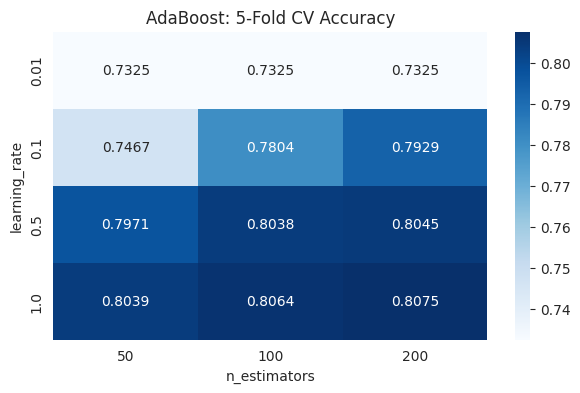

In [12]:
# Heatmap of CV accuracy for every parameter combination
ada_cv = pd.DataFrame(ada_grid.cv_results_)
pivot = ada_cv.pivot(index="param_learning_rate", columns="param_n_estimators", values="mean_test_score")

plt.figure(figsize=(7,4))
sns.heatmap(pivot.astype(float), annot=True, fmt=".4f", cmap="Blues")
plt.title("AdaBoost: 5-Fold CV Accuracy")
plt.xlabel("n_estimators")
plt.ylabel("learning_rate")
plt.show()

## 5. Tune Gradient Boosting
3 x 4 x 3 = 36 combinations, each cross-validated 5 times (180 model fits), so this cell is the slowest in the notebook. `max_depth` controls how complex each individual tree is.

In [13]:
gb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 7]
}

gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42), gb_param_grid,
                       cv=5, scoring="accuracy", n_jobs=-1)
gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:", gb_grid.best_params_)
print(f"Best CV accuracy: {gb_grid.best_score_:.4f}")

Best Gradient Boosting parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best CV accuracy: 0.8089


In [14]:
# Top 5 parameter combinations by CV accuracy
gb_cv = pd.DataFrame(gb_grid.cv_results_)
gb_cv[["param_n_estimators", "param_learning_rate", "param_max_depth", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(5).round(4)

,param_n_estimators,param_learning_rate,param_max_depth,mean_test_score,std_test_score
18,100,0.10,3,0.8089,0.0091
10,200,0.05,3,0.8068,0.0078
11,300,0.05,3,0.8064,0.0093
9,100,0.05,3,0.8062,0.0078
2,300,0.01,3,0.8047,0.0078


## 6. Final Comparison
Fit both tuned models on the full training set, then report test accuracy, F1-score and ROC-AUC.

In [15]:
# Re-fit each model with its best parameters on the full training set
best_ada = AdaBoostClassifier(random_state=42, **ada_grid.best_params_)
best_ada.fit(X_train, y_train)

best_gb = GradientBoostingClassifier(random_state=42, **gb_grid.best_params_)
best_gb.fit(X_train, y_train)

ada_tuned_metrics = evaluate(best_ada, "AdaBoost (tuned)")
gb_tuned_metrics = evaluate(best_gb, "Gradient Boosting (tuned)")

--- AdaBoost (tuned) ---
Accuracy:  0.7924
Precision: 0.6340
Recall:    0.4803
F1-score:  0.5466
Confusion Matrix:
[[1173  127]
 [ 238  220]]

--- Gradient Boosting (tuned) ---
Accuracy:  0.7918
Precision: 0.6271
Recall:    0.4956
F1-score:  0.5537
Confusion Matrix:
[[1165  135]
 [ 231  227]]



All four models on the test set:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
AdaBoost (baseline),0.7935,0.6346,0.4891,0.5524,0.8361
AdaBoost (tuned),0.7924,0.6340,0.4803,0.5466,0.8355
Gradient Boosting (baseline),0.7918,0.6271,0.4956,0.5537,0.8342
Gradient Boosting (tuned),0.7918,0.6271,0.4956,0.5537,0.8342


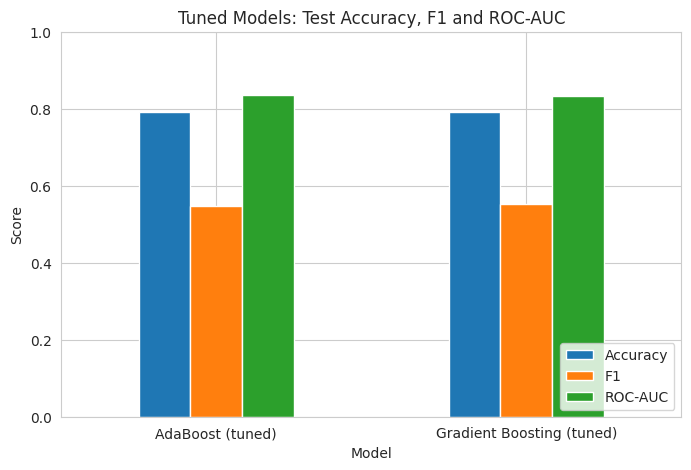

In [16]:
final_df = pd.DataFrame([ada_metrics, ada_tuned_metrics, gb_metrics, gb_tuned_metrics]).set_index("Model")
print("All four models on the test set:")
display(final_df.round(4))

# The three metrics the problem asks for, tuned models only
tuned_df = final_df.loc[["AdaBoost (tuned)", "Gradient Boosting (tuned)"], ["Accuracy", "F1", "ROC-AUC"]]
tuned_df.plot(kind="bar", figsize=(8,5))
plt.title("Tuned Models: Test Accuracy, F1 and ROC-AUC")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

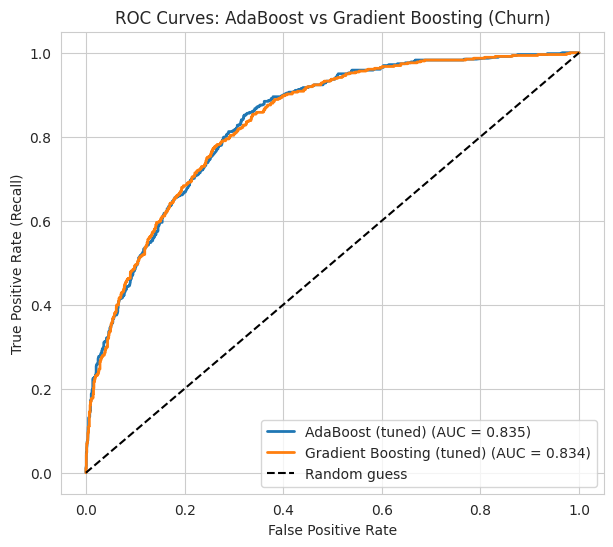

In [17]:
# ROC curves for both tuned models on the same figure
plt.figure(figsize=(7,6))
for name, model in [("AdaBoost (tuned)", best_ada), ("Gradient Boosting (tuned)", best_gb)]:
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves: AdaBoost vs Gradient Boosting (Churn)")
plt.legend(loc="lower right")
plt.show()

In [18]:
# Which model performs better? Compare on each metric and print the verdict from your own results
ada_row = final_df.loc["AdaBoost (tuned)"]
gb_row = final_df.loc["Gradient Boosting (tuned)"]

for metric in ["Accuracy", "F1", "ROC-AUC"]:
    diff = gb_row[metric] - ada_row[metric]
    leader = "Gradient Boosting" if diff > 0 else "AdaBoost" if diff < 0 else "Tie"
    print(f"{metric:9s}: AdaBoost = {ada_row[metric]:.4f} | Gradient Boosting = {gb_row[metric]:.4f} | leader: {leader} (gap {abs(diff):.4f})")

Accuracy : AdaBoost = 0.7924 | Gradient Boosting = 0.7918 | leader: AdaBoost (gap 0.0006)
F1       : AdaBoost = 0.5466 | Gradient Boosting = 0.5537 | leader: Gradient Boosting (gap 0.0071)
ROC-AUC  : AdaBoost = 0.8355 | Gradient Boosting = 0.8342 | leader: AdaBoost (gap 0.0013)


**Which model performs better for churn prediction? Why?**

Use the printout above for the actual answer, then explain it with these ideas:

- **ROC-AUC** measures how well a model ranks churners above non-churners across all thresholds, so it is the fairest single number on imbalanced data. Accuracy and F1 depend on the default 0.5 cutoff.
- Gradient Boosting usually has a small edge here because it optimizes a smooth loss directly and has more tuning freedom (tree depth and learning rate together), so it can capture feature interactions such as *month-to-month contract + fiber internet + short tenure*. AdaBoost typically uses very shallow trees by default, which limits that.
- The gap is often small. If the two models are within a point or so on ROC-AUC, say they perform about equally and note that the choice may come down to training time, which favors AdaBoost.
- If recall is low for both, the models are missing many real churners. The decision threshold (or class weights) can be adjusted to trade some false alarms for more caught churners, which is usually worthwhile because losing a customer costs more than a retention offer.

## 7. Feature Importance (Optional)
Top 15 features for the best Gradient Boosting model.

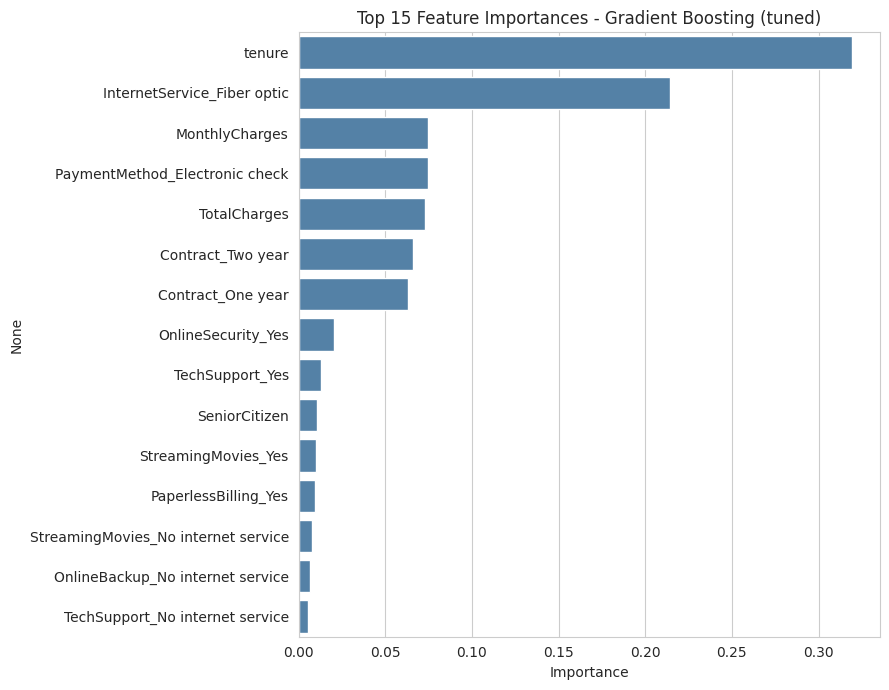

tenure                                 0.3195
InternetService_Fiber optic            0.2142
MonthlyCharges                         0.0748
PaymentMethod_Electronic check         0.0744
TotalCharges                           0.0729
Contract_Two year                      0.0661
Contract_One year                      0.0631
OnlineSecurity_Yes                     0.0205
TechSupport_Yes                        0.0132
SeniorCitizen                          0.0106
StreamingMovies_Yes                    0.0098
PaperlessBilling_Yes                   0.0097
StreamingMovies_No internet service    0.0078
OnlineBackup_No internet service       0.0066
TechSupport_No internet service        0.0052
dtype: float64


In [19]:
importances = pd.Series(best_gb.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9,7))
sns.barplot(x=importances.values, y=importances.index, color="steelblue")
plt.title("Top 15 Feature Importances - Gradient Boosting (tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.round(4))

**Which features drive churn the most?**

Read the answer from your chart. On this dataset the top drivers are commonly **tenure**, **total and monthly charges**, **contract type** (month-to-month vs. longer contracts), **internet service type** (fiber optic) and **payment method** (electronic check). Typical interpretation: newer customers on flexible month-to-month plans with higher bills are the most likely to leave.

Caveat: importance shows what the model relied on to predict, not proof of cause, and impurity-based importance can favor numeric features with many distinct values (like charges).